In [1]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)

In [2]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=True):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [4]:
observables2 = ['pt','m','q2','rg','zg','mg','w','reject']
observabless2 = ['pts','ms','q2s','rgs','zgs','mgs','ws','rejects']
inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all0818_2.root']
treeName = ["MatchedTree"]

In [5]:
def getEff(pythiaFile, pythiaCuts):
    df = applyCut(addNewBranches(getData(observables2+observabless2, inputFiles[0], treeName[0])),pythiaCuts)
    match_miss, _ = np.histogram(df[ob], range=(range_low,range_high), bins=bins, weights=df['w'])
    match, _ = np.histogram(df[(df.ms>1) & (df.pts>15)][ob], range=(range_low,range_high), bins=bins, weights=df[(df.ms>1) & (df.pts>15)]['w'])
    print(match/(1e-50+match_miss))
    return match/(1e-50+match_miss)

In [6]:
def addNewBranches(inputDataframe):
    df_temp = inputDataframe
    df_temp.eval('dm=m-mg',inplace=True)
    df_temp.eval('dm_frac=dm/m',inplace=True)
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp[df_temp.a<0.000001]['a'] = 0
    df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
    df_temp.mask(df_temp.isna(),-4.1,inplace=True)
    return df_temp

In [7]:
def getFull(effFile, pythiaCuts, ofCsvPath, ofCuts, it, nom=False, filelist=None):

    if filelist is None:
        filelist = np.arange(1,21)
        
    df2s = []
    for i in filelist:
        
        df_temp = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
        df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
        df_temp[df_temp.a<0.000001]['a'] = 0
        df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
        df_temp.mask(df_temp.isna(),-4.1,inplace=True)
        df_temp['weight'] = pd.read_csv(path+ofCsvPath+'it'+str(it)+'_seed'+str(i)+'.csv', low_memory=False)
        df2s.append(applyCut(df_temp, ofCuts))
    y2s = []
    for i in range(0, len(filelist)):
        y2s.append(np.histogram(df2s[i][ob], range=(range_low,range_high), bins=bins, weights=df2s[i]['weight'], density=True)[0])
    y2 = np.average(y2s, axis=0)
    y2_err = np.std(y2s, axis=0)
    
    y = y2/(1e-50+getEff(effFile, pythiaCuts))
    norm = sum(y)
    y = y/norm
    if (nom==False):
        err_seed=0
        err_it=0
    else:
        err_seed = y2_err/(np.sqrt(len(filelist))*norm) # use standard error

    return y/sum(y), err_seed/sum(y)

In [8]:
def getErrUnf(y_nom,y_hw,y_p8,err_seed):
    err4 = np.array(y_nom/sum(y_nom))-np.array(y_hw/sum(y_hw))
    err5 = np.array(y_nom/sum(y_nom))-np.array(y_p8/sum(y_p8))
    err6 = err_seed/sum(y_nom)
    err_unf=[]
    for i in range(0,len(err4)):
        err_unf.append( np.sqrt( (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
    return np.array(err_unf)

In [9]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [10]:
path = '/gpfs/gibbs/project/caines/ys668/run12/csvs/'
nom_path = 'newemb_6d_largebatch_092723/'
hw_path = 'herwig_newemb_7dreweight_6dunfold_largebatch_092723/'
py8_path = 'pythia8_newemb_7dreweight_6dunfold_largebatch_092723/'

In [11]:
it_mean = 15

In [12]:
ob = 'loga'
range_low = -4.5
range_high = -0.
bins = 9
binwidth = (range_high - range_low)/bins

In [13]:
x = np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)

In [14]:
cut = '20<pt<30 and 0.4<zg<0.5 and 0<rg<0.1'
y_nom_1, err_seed_1 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_1, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_1, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_1 = getErrUnf(y_nom_1,y_hw_1,y_p8_1,err_seed_1)

/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.28836012 0.39559536 0.39147367 0.44447023 0.52726036 0.54520157
 0.52397572 0.4466888  0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.28836012 0.39559536 0.39147367 0.44447023 0.52726036 0.54520157
 0.52397572 0.4466888  0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.28836012 0.39559536 0.39147367 0.44447023 0.52726036 0.54520157
 0.52397572 0.4466888  0.        ]


In [15]:
cut = '20<pt<30 and 0.4<zg<0.5 and 0.15<rg<0.25'
y_nom_2, err_seed_2 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_2, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_2, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_2 = getErrUnf(y_nom_2,y_hw_2,y_p8_2,err_seed_2)

/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62023113 0.         0.69029866 0.6270307  0.66013933 0.65412448
 0.62343038 0.5964015  0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62023113 0.         0.69029866 0.6270307  0.66013933 0.65412448
 0.62343038 0.5964015  0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62023113 0.         0.69029866 0.6270307  0.66013933 0.65412448
 0.62343038 0.5964015  0.        ]


In [16]:
cut = '20<pt<30 and 0.1<zg<0.2 and 0.15<rg<0.25'
y_nom_3, err_seed_3 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_3, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_3, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_3 = getErrUnf(y_nom_3,y_hw_3,y_p8_3,err_seed_3)

/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.58585645 0.5        0.69062288 0.62512902 0.63887227 0.64737677
 0.60577638 0.61456012 0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.58585645 0.5        0.69062288 0.62512902 0.63887227 0.64737677
 0.60577638 0.61456012 0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.58585645 0.5        0.69062288 0.62512902 0.63887227 0.64737677
 0.60577638 0.61456012 0.        ]


In [17]:
cut = '20<pt<30 and 0.1<zg<0.2 and 0.3<rg<0.4'
y_nom_4, err_seed_4 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_4, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_4, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_4 = getErrUnf(y_nom_4,y_hw_4,y_p8_4,err_seed_4)

/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62225626 0.         0.55165904 0.67847717 0.64960284 0.65288744
 0.65727643 0.10540577 0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62225626 0.         0.55165904 0.67847717 0.64960284 0.65288744
 0.65727643 0.10540577 0.        ]


/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_2866463/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62225626 0.         0.55165904 0.67847717 0.64960284 0.65288744
 0.65727643 0.10540577 0.        ]


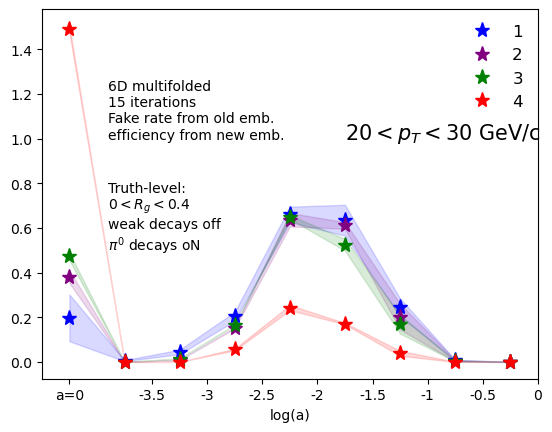

In [18]:
fig, ax = plt.subplots()
line1, = plt.plot(x, 2*y_nom_1/sum(y_nom_1), label='1', color='b', marker='*', markersize=11, ls='none')
linea = plt.fill_between(x, 2*(y_nom_1/sum(y_nom_1)-err_unf_1), 2*(y_nom_1/sum(y_nom_1)+err_unf_1), color='b', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line2, = plt.plot(x, 2*y_nom_2/sum(y_nom_2), label='2', color='purple', marker='*', markersize=11, ls='none')
lineb = plt.fill_between(x, 2*(y_nom_2/sum(y_nom_2)-err_unf_2), 2*(y_nom_2/sum(y_nom_2)+err_unf_2), color='purple', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line3, = plt.plot(x, 2*y_nom_3/sum(y_nom_3), label='3', color='g', marker='*', markersize=11, ls='none')
linec = plt.fill_between(x, 2*(y_nom_3/sum(y_nom_3)-err_unf_3), 2*(y_nom_3/sum(y_nom_3)+err_unf_3), color='g', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line4, = plt.plot(x, 2*y_nom_4/sum(y_nom_4), label='4', color='r', marker='*', markersize=11, ls='none')
lined = plt.fill_between(x, 2*(y_nom_4/sum(y_nom_4)-err_unf_4), 2*(y_nom_4/sum(y_nom_4)+err_unf_4), color='r', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
plt.text(-1.75, 1,'$20<p_T<30$ GeV/c', fontsize=15)
plt.text(-3.9, 1.0, '6D multifolded\n15 iterations\nFake rate from old emb.\nefficiency from new emb.')
plt.text(-3.9, 0.5,'Truth-level:\n$0<R_g<0.4$\nweak decays off\n$\pi^0$ decays oN')
plt.xlabel('log(a)')
plt.xticks([-4.25,-3.5,-3,-2.5,-2,-1.5,-1,-.5,0],['a=0','-3.5','-3','-2.5','-2','-1.5','-1','-0.5','0'])
plt.xlim(-4.5,0.)
l1 = ax.legend(handles=[line1,line2,line3,line4], frameon=False, loc='upper right', fontsize=12)

(-0.07527688678451837, 1.7)

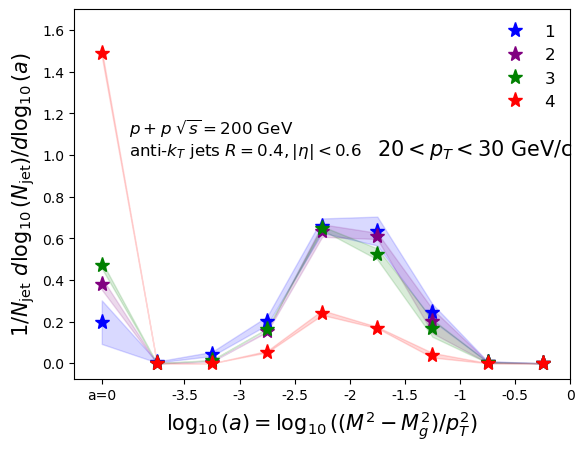

In [22]:
fig, ax = plt.subplots()
line1, = plt.plot(x, 2*y_nom_1/sum(y_nom_1), label='1', color='b', marker='*', markersize=11, ls='none')
linea = plt.fill_between(x, 2*(y_nom_1/sum(y_nom_1)-err_unf_1), 2*(y_nom_1/sum(y_nom_1)+err_unf_1), color='b', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line2, = plt.plot(x, 2*y_nom_2/sum(y_nom_2), label='2', color='purple', marker='*', markersize=11, ls='none')
lineb = plt.fill_between(x, 2*(y_nom_2/sum(y_nom_2)-err_unf_2), 2*(y_nom_2/sum(y_nom_2)+err_unf_2), color='purple', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line3, = plt.plot(x, 2*y_nom_3/sum(y_nom_3), label='3', color='g', marker='*', markersize=11, ls='none')
linec = plt.fill_between(x, 2*(y_nom_3/sum(y_nom_3)-err_unf_3), 2*(y_nom_3/sum(y_nom_3)+err_unf_3), color='g', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line4, = plt.plot(x, 2*y_nom_4/sum(y_nom_4), label='4', color='r', marker='*', markersize=11, ls='none')
lined = plt.fill_between(x, 2*(y_nom_4/sum(y_nom_4)-err_unf_4), 2*(y_nom_4/sum(y_nom_4)+err_unf_4), color='r', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
plt.text(-1.75, 1,'$20<p_T<30$ GeV/c', fontsize=15)
#plt.text(-3.9, 1.0, '6D multifolded\n15 iterations\nFake rate from old emb.\nefficiency from new emb.')
#plt.text(-3.9, 0.5,'Truth-level:\n$0<R_g<0.4$\nweak decays off\n$\pi^0$ decays oN')
plt.text(-4, 1., '$p+p$ $\sqrt{s}=200$ GeV\nanti-$k_T$ jets $R=0.4, |\eta|<0.6$', fontsize=12)
plt.xlabel('log(a)')
plt.xticks([-4.25,-3.5,-3,-2.5,-2,-1.5,-1,-.5,0],['a=0','-3.5','-3','-2.5','-2','-1.5','-1','-0.5','0'])
plt.xlim(-4.5,0.)
l1 = ax.legend(handles=[line1,line2,line3,line4], frameon=False, loc='upper right', fontsize=12)
plt.xlabel('$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$', fontsize=15)
plt.ylabel(r'$1/N_{\mathrm{jet}}$ $d\log_{10}(N_{\mathrm{jet}})/d\log_{10}(a)$', fontsize=15)
plt.ylim(top=1.7)

In [19]:
cut = '20<pt<50 and 0.4<zg<0.5 and 0<rg<0.1'
y_nom_1, err_seed_1 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_1, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_1, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_1 = getErrUnf(y_nom_1,y_hw_1,y_p8_1,err_seed_1)

/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.29890454 0.39813216 0.41936809 0.46820668 0.55034567 0.56733165
 0.53859802 0.45459102 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.29890454 0.39813216 0.41936809 0.46820668 0.55034567 0.56733165
 0.53859802 0.45459102 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.29890454 0.39813216 0.41936809 0.46820668 0.55034567 0.56733165
 0.53859802 0.45459102 0.        ]


In [20]:
cut = '20<pt<50 and 0.4<zg<0.5 and 0.15<rg<0.25'
y_nom_2, err_seed_2 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_2, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_2, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_2 = getErrUnf(y_nom_2,y_hw_2,y_p8_2,err_seed_2)

/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62453293 1.         0.70100915 0.636674   0.66748584 0.66290527
 0.62872034 0.59659255 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62453293 1.         0.70100915 0.636674   0.66748584 0.66290527
 0.62872034 0.59659255 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62453293 1.         0.70100915 0.636674   0.66748584 0.66290527
 0.62872034 0.59659255 0.        ]


In [21]:
cut = '20<pt<50 and 0.1<zg<0.2 and 0.15<rg<0.25'
y_nom_3, err_seed_3 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_3, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_3, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_3 = getErrUnf(y_nom_3,y_hw_3,y_p8_3,err_seed_3)

/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.59582726 0.84805317 0.71255098 0.641902   0.65149181 0.65949158
 0.61513005 0.61934165 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.59582726 0.84805317 0.71255098 0.641902   0.65149181 0.65949158
 0.61513005 0.61934165 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.59582726 0.84805317 0.71255098 0.641902   0.65149181 0.65949158
 0.61513005 0.61934165 0.        ]


In [22]:
cut = '20<pt<50 and 0.1<zg<0.2 and 0.3<rg<0.4'
y_nom_4, err_seed_4 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_4, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_4, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_4 = getErrUnf(y_nom_4,y_hw_4,y_p8_4,err_seed_4)

/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62770988 0.         0.62491801 0.68690537 0.65738476 0.65919539
 0.66110386 0.10540577 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62770988 0.         0.62491801 0.68690537 0.65738476 0.65919539
 0.66110386 0.10540577 0.        ]


/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_4099235/3154088755.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62770988 0.         0.62491801 0.68690537 0.65738476 0.65919539
 0.66110386 0.10540577 0.        ]


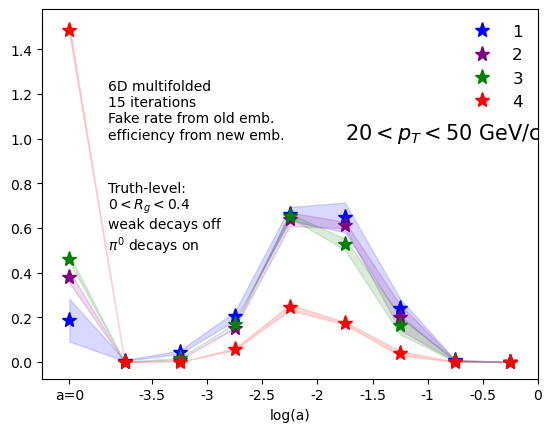

In [23]:
fig, ax = plt.subplots()
line1, = plt.plot(x, 2*y_nom_1/sum(y_nom_1), label='1', color='b', marker='*', markersize=11, ls='none')
linea = plt.fill_between(x, 2*(y_nom_1/sum(y_nom_1)-err_unf_1), 2*(y_nom_1/sum(y_nom_1)+err_unf_1), color='b', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line2, = plt.plot(x, 2*y_nom_2/sum(y_nom_2), label='2', color='purple', marker='*', markersize=11, ls='none')
lineb = plt.fill_between(x, 2*(y_nom_2/sum(y_nom_2)-err_unf_2), 2*(y_nom_2/sum(y_nom_2)+err_unf_2), color='purple', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line3, = plt.plot(x, 2*y_nom_3/sum(y_nom_3), label='3', color='g', marker='*', markersize=11, ls='none')
linec = plt.fill_between(x, 2*(y_nom_3/sum(y_nom_3)-err_unf_3), 2*(y_nom_3/sum(y_nom_3)+err_unf_3), color='g', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line4, = plt.plot(x, 2*y_nom_4/sum(y_nom_4), label='4', color='r', marker='*', markersize=11, ls='none')
lined = plt.fill_between(x, 2*(y_nom_4/sum(y_nom_4)-err_unf_4), 2*(y_nom_4/sum(y_nom_4)+err_unf_4), color='r', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
plt.text(-1.75, 1,'$20<p_T<50$ GeV/c', fontsize=15)
plt.text(-3.9, 1.0, '6D multifolded\n15 iterations\nFake rate from old emb.\nefficiency from new emb.')
plt.text(-3.9, 0.5,'Truth-level:\n$0<R_g<0.4$\nweak decays off\n$\pi^0$ decays on')
plt.xlabel('log(a)')
plt.xticks([-4.25,-3.5,-3,-2.5,-2,-1.5,-1,-.5,0],['a=0','-3.5','-3','-2.5','-2','-1.5','-1','-0.5','0'])
plt.xlim(-4.5,0.)
l1 = ax.legend(handles=[line1,line2,line3,line4], frameon=False, loc='upper right', fontsize=12)

In [108]:
itmean = 10

In [109]:
ob = 'loga'
range_low = -4.5
range_high = -0.
bins = 9
binwidth = (range_high - range_low)/bins

In [110]:
x = np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)

In [112]:
cut = '20<pt<30 and 0.4<zg<0.5 and 0<rg<0.1'
y_nom_1, err_seed_1 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_1, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_1, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_1 = getErrUnf(y_nom_1,y_hw_1,y_p8_1,err_seed_1)

/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.28836012 0.39559536 0.39147367 0.44447023 0.52726036 0.54520157
 0.52397572 0.4466888  0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.28836012 0.39559536 0.39147367 0.44447023 0.52726036 0.54520157
 0.52397572 0.4466888  0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.28836012 0.39559536 0.39147367 0.44447023 0.52726036 0.54520157
 0.52397572 0.4466888  0.        ]


In [113]:
cut = '20<pt<30 and 0.4<zg<0.5 and 0.15<rg<0.25'
y_nom_2, err_seed_2 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_2, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_2, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_2 = getErrUnf(y_nom_2,y_hw_2,y_p8_2,err_seed_2)

/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62023113 0.         0.69029866 0.6270307  0.66013933 0.65412448
 0.62343038 0.5964015  0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62023113 0.         0.69029866 0.6270307  0.66013933 0.65412448
 0.62343038 0.5964015  0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62023113 0.         0.69029866 0.6270307  0.66013933 0.65412448
 0.62343038 0.5964015  0.        ]


In [114]:
cut = '20<pt<30 and 0.1<zg<0.2 and 0.15<rg<0.25'
y_nom_3, err_seed_3 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_3, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_3, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_3 = getErrUnf(y_nom_3,y_hw_3,y_p8_3,err_seed_3)

/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.58585645 0.5        0.69062288 0.62512902 0.63887227 0.64737677
 0.60577638 0.61456012 0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.58585645 0.5        0.69062288 0.62512902 0.63887227 0.64737677
 0.60577638 0.61456012 0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.58585645 0.5        0.69062288 0.62512902 0.63887227 0.64737677
 0.60577638 0.61456012 0.        ]


In [115]:
cut = '20<pt<30 and 0.1<zg<0.2 and 0.3<rg<0.4'
y_nom_4, err_seed_4 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_4, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_4, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_4 = getErrUnf(y_nom_4,y_hw_4,y_p8_4,err_seed_4)

/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62225626 0.         0.55165904 0.67847717 0.64960284 0.65288744
 0.65727643 0.10540577 0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62225626 0.         0.55165904 0.67847717 0.64960284 0.65288744
 0.65727643 0.10540577 0.        ]


/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/tmp/ipykernel_3143142/3483054694.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/li

[0.62225626 0.         0.55165904 0.67847717 0.64960284 0.65288744
 0.65727643 0.10540577 0.        ]


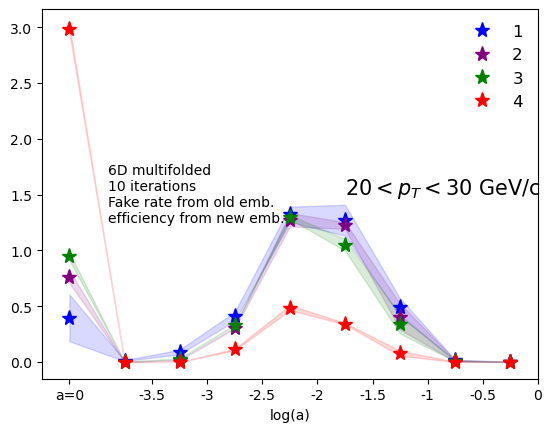

In [116]:
fig, ax = plt.subplots()
line1, = plt.plot(x, 4*y_nom_1/sum(y_nom_1), label='1', color='b', marker='*', markersize=11, ls='none')
linea = plt.fill_between(x, 4*(y_nom_1/sum(y_nom_1)-err_unf_1), 4*(y_nom_1/sum(y_nom_1)+err_unf_1), color='b', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line2, = plt.plot(x, 4*y_nom_2/sum(y_nom_2), label='2', color='purple', marker='*', markersize=11, ls='none')
lineb = plt.fill_between(x, 4*(y_nom_2/sum(y_nom_2)-err_unf_2), 4*(y_nom_2/sum(y_nom_2)+err_unf_2), color='purple', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line3, = plt.plot(x, 4*y_nom_3/sum(y_nom_3), label='3', color='g', marker='*', markersize=11, ls='none')
linec = plt.fill_between(x, 4*(y_nom_3/sum(y_nom_3)-err_unf_3), 4*(y_nom_3/sum(y_nom_3)+err_unf_3), color='g', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line4, = plt.plot(x, 4*y_nom_4/sum(y_nom_4), label='4', color='r', marker='*', markersize=11, ls='none')
lined = plt.fill_between(x, 4*(y_nom_4/sum(y_nom_4)-err_unf_4), 4*(y_nom_4/sum(y_nom_4)+err_unf_4), color='r', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
plt.text(-1.75, 1.5,'$20<p_T<30$ GeV/c', fontsize=15)
plt.text(-3.9, 1.25, '6D multifolded\n10 iterations\nFake rate from old emb.\nefficiency from new emb.')
plt.xlabel('log(a)')
plt.xticks([-4.25,-3.5,-3,-2.5,-2,-1.5,-1,-.5,0],['a=0','-3.5','-3','-2.5','-2','-1.5','-1','-0.5','0'])
plt.xlim(-4.5,0.)
l1 = ax.legend(handles=[line1,line2,line3,line4], frameon=False, loc='upper right', fontsize=12)
plt.savefig('10iteration.png')

In [ ]:
def getAvgW(it,folder_name):
    dfs=[]
    for i in range(1,21):
        dfs.append(pd.read_csv('/gpfs/gibbs/project/caines/ys668/run12/csvs/'+folder_name+'it'+str(it)+'_seed'+str(i)+'.csv', low_memory=False))
    w = []
    for i in range(0, len(dfs)):
        w.append(np.asarray(dfs[i]['weight']))
    return np.average(w,axis=0), np.std(w,axis=0)

In [ ]:
def makeHist(it,ofCsvPath):
    
    multifold_ws = getAvgW(it,ofCsvPath)[0]
    
    df = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
    df.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df[df.a<0.000001]['a'] = 0
    df[['loga']] = np.log10(df[['a']].replace(0, np.nan))
    df.mask(df.isna(),-4.1,inplace=True)
    df['w'] = multifold_ws
    cut = '20<pt<30 and 0.4<zg<0.5 and 0<rg<0.1'
    df = applyCut(df, cut)
    of_histgen, of_histgen_unc = np.histogram(df['loga'], weights=df['w'], range=(range_low,range_high), bins=bins, density=True)

    return of_histgen, of_histgen_unc

In [ ]:
nom1_y, nom1_yerr = makeHist(1,nom_path)
#nom2_y, nom2_yerr = makeHist(2,nom_path)
#nom3_y, nom3_yerr = makeHist(3,nom_path)
#nom4_y, nom4_yerr = makeHist(4,nom_path)
#nom5_y, nom5_yerr = makeHist(5,nom_path)
nom6_y, nom6_yerr = makeHist(6,nom_path)
#nom7_y, nom7_yerr = makeHist(7,nom_path)
#nom8_y, nom8_yerr = makeHist(8,nom_path)
#nom9_y, nom9_yerr = makeHist(9,nom_path)
nom10_y, nom10_yerr = makeHist(10,nom_path)
nom11_y, nom11_yerr = makeHist(11,nom_path)
nom12_y, nom12_yerr = makeHist(12,nom_path)
nom13_y, nom13_yerr = makeHist(13,nom_path)
nom14_y, nom14_yerr = makeHist(14,nom_path)
nom15_y, nom15_yerr = makeHist(15,nom_path)
nom16_y, nom16_yerr = makeHist(16,nom_path)
nom17_y, nom17_yerr = makeHist(17,nom_path)
nom18_y, nom18_yerr = makeHist(18,nom_path)
nom19_y, nom19_yerr = makeHist(19,nom_path)
nom20_y, nom20_yerr = makeHist(20,nom_path)
#nom25_y, nom25_yerr = makeHist(25,nom_path)
#nom30_y, nom30_yerr = makeHist(30,nom_path)
#nom21_y, nom21_yerr = makeHist(21,nom_path)
#nom26_y, nom26_yerr = makeHist(26,nom_path)

In [ ]:
plt.cla()
plt.errorbar(x, nom1_y, capsize=1, label='1')
#plt.errorbar(x, nom2_y, capsize=1, label='2')
#plt.errorbar(x, nom3_y, capsize=1, label='3')
#plt.errorbar(x, nom4_y, capsize=1, label='4')
#plt.errorbar(x, nom5_y, capsize=1, label='5')
plt.errorbar(x, nom6_y, capsize=1, label='6')
#plt.errorbar(x, nom7_y, capsize=1, label='7')
#plt.errorbar(x, nom8_y, capsize=1, label='8')
#plt.errorbar(x, nom9_y, capsize=1, label='9')
plt.errorbar(x, nom10_y, capsize=1, label='10')
plt.errorbar(x, nom11_y, capsize=1, label='11')
plt.errorbar(x, nom12_y, capsize=1, label='12')
plt.errorbar(x, nom14_y, capsize=1, label='14')
plt.errorbar(x, nom16_y, capsize=1, label='16')
plt.errorbar(x, nom18_y, capsize=1, label='18')
plt.errorbar(x, nom20_y, capsize=1, label='20')
plt.ylim(0,0.9)
plt.xlabel('log(a)')
plt.legend(framealpha=1)   
plt.title('nominal')
plt.savefig('nominal.png')

In [ ]:
py1_y, py1_yerr = makeHist(1,py8_path)
#py2_y, py2_yerr = makeHist(2,py8_path)
#py3_y, py3_yerr = makeHist(3,py8_path)
#py4_y, py4_yerr = makeHist(4,py8_path)
#py5_y, py5_yerr = makeHist(5,py8_path)
py6_y, py6_yerr = makeHist(6,py8_path)
#py7_y, py7_yerr = makeHist(7,py8_path)
#py8_y, py8_yerr = makeHist(8,py8_path)
#py9_y, py9_yerr = makeHist(9,py8_path)
py10_y, py10_yerr = makeHist(10,py8_path)
py11_y, py11_yerr = makeHist(11,py8_path)
py12_y, py12_yerr = makeHist(12,py8_path)
py13_y, py13_yerr = makeHist(13,py8_path)
py14_y, py14_yerr = makeHist(14,py8_path)
py15_y, py15_yerr = makeHist(15,py8_path)
py16_y, py16_yerr = makeHist(16,py8_path)
py17_y, py17_yerr = makeHist(17,py8_path)
py18_y, py18_yerr = makeHist(18,py8_path)
py19_y, py19_yerr = makeHist(19,py8_path)
py20_y, py20_yerr = makeHist(20,py8_path)
#py25_y, py25_yerr = makeHist(25,py8_path)
#py30_y, py30_yerr = makeHist(30,py8_path)
#py21_y, py21_yerr = makeHist(21,py8_path)
#py26_y, py26_yerr = makeHist(26,py8_path)

In [ ]:
plt.cla()
plt.errorbar(x, py1_y, capsize=1, label='1')
#plt.errorbar(x, py2_y, capsize=1, label='2')
#plt.errorbar(x, py3_y, capsize=1, label='3')
#plt.errorbar(x, py4_y, capsize=1, label='4')
#plt.errorbar(x, py5_y, capsize=1, label='5')
plt.errorbar(x, py6_y, capsize=1, label='6')
#plt.errorbar(x, py7_y, capsize=1, label='7')
#plt.errorbar(x, py8_y, capsize=1, label='8')
#plt.errorbar(x, py9_y, capsize=1, label='9')
plt.errorbar(x, py10_y, capsize=1, label='10')
plt.errorbar(x, py11_y, capsize=1, label='11')
plt.errorbar(x, py12_y, capsize=1, label='12')
plt.errorbar(x, py14_y, capsize=1, label='14')
plt.errorbar(x, py16_y, capsize=1, label='16')
plt.errorbar(x, py18_y, capsize=1, label='18')
plt.errorbar(x, py20_y, capsize=1, label='20')
plt.ylim(0,0.9)
plt.xlabel('log(a)')
plt.legend(framealpha=1)   
plt.title('pythia8')
plt.savefig('pythia8.png')

In [ ]:
hw1_y, hw1_yerr = makeHist(1,hw_path)
#hw2_y, hw2_yerr = makeHist(2,hw_path)
#hw3_y, hw3_yerr = makeHist(3,hw_path)
#hw4_y, hw4_yerr = makeHist(4,hw_path)
#hw5_y, hw5_yerr = makeHist(5,hw_path)
hw6_y, hw6_yerr = makeHist(6,hw_path)
#hw7_y, hw7_yerr = makeHist(7,hw_path)
#hw_y, hw_yerr = makeHist(8,hw_path)
#hw9_y, hw9_yerr = makeHist(9,hw_path)
hw10_y, hw10_yerr = makeHist(10,hw_path)
hw11_y, hw11_yerr = makeHist(11,hw_path)
hw12_y, hw12_yerr = makeHist(12,hw_path)
hw13_y, hw13_yerr = makeHist(13,hw_path)
hw14_y, hw14_yerr = makeHist(14,hw_path)
hw15_y, hw15_yerr = makeHist(15,hw_path)
hw16_y, hw16_yerr = makeHist(16,hw_path)
hw17_y, hw17_yerr = makeHist(17,hw_path)
hw18_y, hw18_yerr = makeHist(18,hw_path)
hw19_y, hw19_yerr = makeHist(19,hw_path)
hw20_y, hw20_yerr = makeHist(20,hw_path)
#hw25_y, hw25_yerr = makeHist(25,hw_path)
#hw30_y, hw30_yerr = makeHist(30,hw_path)
#hw21_y, hw21_yerr = makeHist(21,hw_path)
#hw26_y, hw26_yerr = makeHist(26,hw_path)

In [ ]:
plt.cla()
plt.errorbar(x, hw1_y, capsize=1, label='1')
#plt.errorbar(x, hw2_y, capsize=1, label='2')
#plt.errorbar(x, hw3_y, capsize=1, label='3')
#plt.errorbar(x, hw4_y, capsize=1, label='4')
#plt.errorbar(x, hw5_y, capsize=1, label='5')
plt.errorbar(x, hw6_y, capsize=1, label='6')
#plt.errorbar(x, hw7_y, capsize=1, label='7')
#plt.errorbar(x, hw8_y, capsize=1, label='8')
#plt.errorbar(x, hw9_y, capsize=1, label='9')
plt.errorbar(x, hw10_y, capsize=1, label='10')
plt.errorbar(x, hw11_y, capsize=1, label='11')
plt.errorbar(x, hw12_y, capsize=1, label='12')
plt.errorbar(x, hw14_y, capsize=1, label='14')
plt.errorbar(x, hw16_y, capsize=1, label='16')
plt.errorbar(x, hw18_y, capsize=1, label='18')
plt.errorbar(x, hw20_y, capsize=1, label='20')
plt.ylim(0,0.9)
plt.xlabel('log(a)')
plt.legend(framealpha=1)   
plt.title('herwig')
plt.savefig('herwig.png')